# 03 - Fenêtrage multi-échelle et extraction des variables

**Principe de l'approche 1** : on découpe les signaux en fenêtres et on résume chaque fenêtre par des
statistiques ; un modèle de classification classique apprend ensuite à associer ces résumés à un comportement.

**Partis pris** (modifiables dans `src/config.py`) :

| Choix | Valeur | Justification |
|---|---|---|
| Cœur de fenêtre (porte le label) | 1 s (100 points) | assez court pour suivre les changements de comportement |
| Pas entre fenêtres | 0,5 s | 50 % de recouvrement : plus d'exemples, transitions mieux suivies |
| Échelles de contexte | 1 s, 2 s, 4 s centrées sur le cœur | comportements lents (renifler, manger) vs rapides (galop) |
| Pureté minimale du label | 80 % du cœur | exclut les fenêtres à cheval sur deux comportements (label ambigu) |
| Fenêtres et ruptures | jamais à cheval sur une rupture temporelle | évite des statistiques calculées sur un signal recollé |

**Variables** (par échelle) : moyenne, écart-type, min, max des 12 axes, des 4 normes et des 4 taux de
variation de la norme ; fréquence dominante, énergie et entropie spectrales des 4 normes ; ratios cou/dos.
Les trois échelles sont calculées sur **les mêmes fenêtres**, donc comparables à données identiques.

Chaque fenêtre garde ses métadonnées (chien, séance, temps de début et de fin) et ses `Behavior_1/2/3`
calculés au moment du découpage (correction du désalignement de la première version).

In [1]:
import sys
from pathlib import Path

# Racine du projet ajoutée au chemin d'import (le notebook est dans notebooks/)
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from src import config as cfg
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

import time
from src import data, features, labels, viz

In [2]:
moves = data.load_moves()
t0 = time.time()
windows = features.build_windows(moves, scales_s=cfg.SCALES_S, label_window_s=cfg.LABEL_WINDOW_S,
                                 step_s=cfg.STEP_S, verbose=False)
print(f"{len(windows):,} fenêtres construites en {time.time() - t0:.0f} s")
data.save_table(windows, cfg.WINDOWS_FILE)
print("Enregistré :", cfg.WINDOWS_FILE)

211,761 fenêtres construites en 36 s
Enregistré : C:\Users\Cours APT\Documents\dog-behavior-analysis_2\dog-behavior-analysis\data\processed\windows.parquet


## 1. Annotation et pureté des fenêtres

Fenêtres dont le cœur est annoté au moins à 50 % : 62.2%


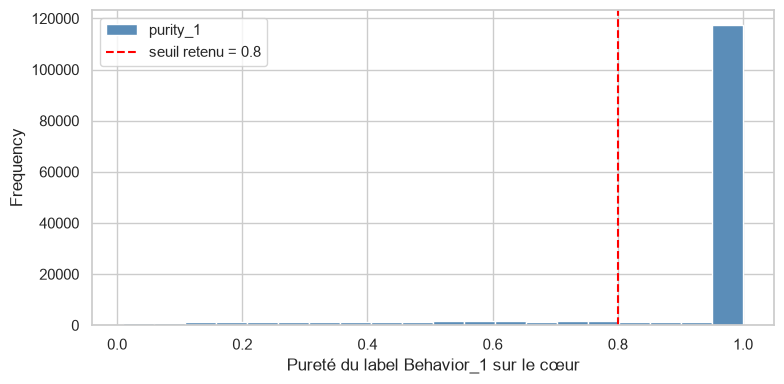

In [3]:
print(f"Fenêtres dont le cœur est annoté au moins à 50 % : {(windows['labelled_1'] >= 0.5).mean():.1%}")
fig, ax = plt.subplots(figsize=(8, 4))
windows.loc[windows["purity_1"] > 0, "purity_1"].plot.hist(bins=20, ax=ax, color="#5b8db8")
ax.axvline(cfg.MIN_PURITY, color="red", ls="--", label=f"seuil retenu = {cfg.MIN_PURITY}")
ax.set_xlabel("Pureté du label Behavior_1 sur le cœur"); ax.legend()
plt.tight_layout(); viz.savefig(fig, "03_purete"); plt.show()

**Effet du seuil de pureté** : un seuil plus strict donne des labels plus fiables mais moins d'exemples,
et retire surtout les fenêtres de transition (les plus difficiles). C'est un compromis à présenter.

In [4]:
rows = {}
for p in [0.5, 0.8, 1.0]:
    rows[f"pureté >= {p}"] = labels.select_task_windows(windows, "general", min_purity=p)["target"].value_counts()
effet = pd.DataFrame(rows).fillna(0).astype(int).sort_values("pureté >= 0.5", ascending=False)
effet.loc["TOTAL"] = effet.sum()
display(effet)

,pureté >= 0.5,pureté >= 0.8,pureté >= 1.0
target,,,
Lying chest,20655,20329,20143
Sniffing,20319,19230,18546
Playing,17256,16490,15973
Panting,16748,15194,14310
Walking,14637,12963,11891
Trotting,14391,13299,12593
Sitting,10213,9933,9779
Standing,8995,8553,8255
Eating,3315,2371,1790


## 2. Jeux de variables comparés

In [5]:
for name in features.FEATURE_SET_NAMES:
    print(f"{name:<22} : {len(features.feature_set(windows, name)):>4} variables")

ancienne_baseline_1s   :   42 variables
complet_1s             :   94 variables
multi_echelle          :  282 variables


## 3. Quelques variables par comportement (chiens d'apprentissage uniquement)

On regarde uniquement les chiens du train : l'exploration ne doit pas influencer nos choix à partir du test.

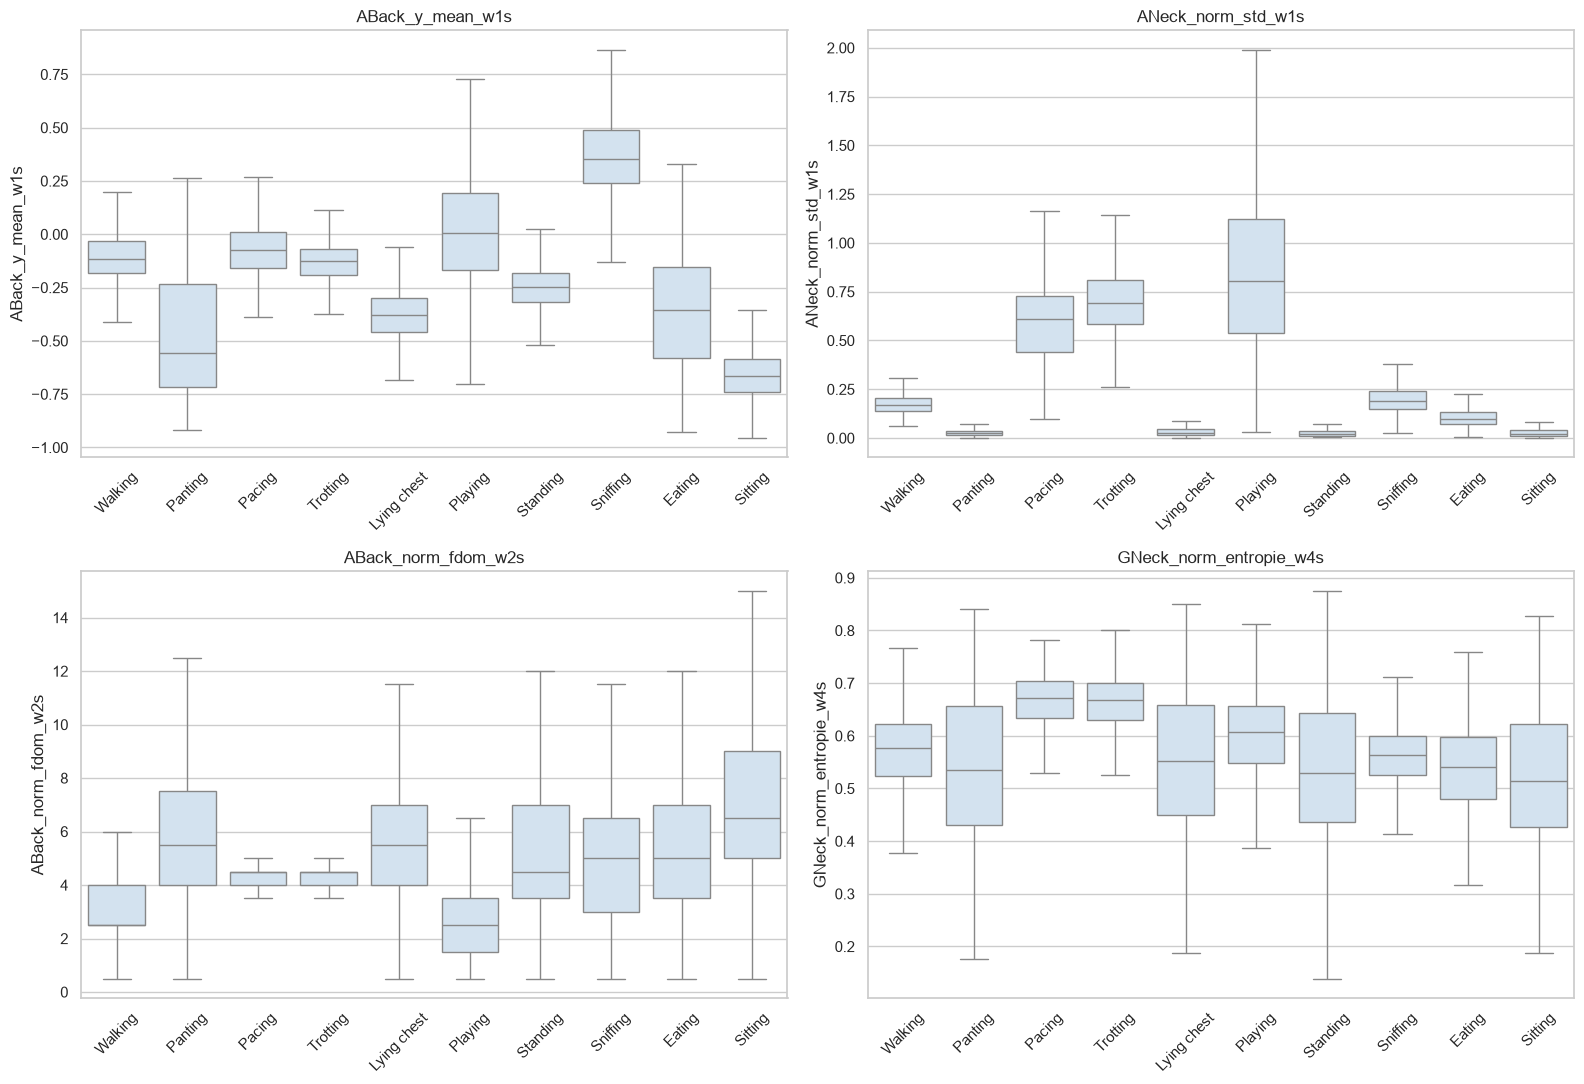

In [6]:
train_ids, _ = data.load_split()
tr = labels.select_task_windows(windows[windows["DogID"].isin(train_ids)], "general")
top = tr["target"].value_counts().nlargest(10).index
tr = tr[tr["target"].isin(top)]
a_tracer = ["ABack_y_mean_w1s", "ANeck_norm_std_w1s", "ABack_norm_fdom_w2s", "GNeck_norm_entropie_w4s"]
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
for ax, f in zip(axes.flatten(), a_tracer):
    sns.boxplot(data=tr, x="target", y=f, ax=ax, showfliers=False, color="#cfe2f3")
    ax.set_title(f); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); viz.savefig(fig, "03_variables_par_comportement"); plt.show()

Lecture attendue : la moyenne d'un axe d'accélération du dos sépare les postures (orientation de la
gravité) ; la fréquence dominante sépare marche / trot / galop ; l'écart-type du cou capte les mouvements
de tête (renifler, manger). C'est la justification « physique » des variables choisies.